In [2]:
import os
os.environ["PYTHONHASHSEED"] = str(42)
os.environ["CUDA_VISIBLE_DEVICES"]="0"

import torch
from sentence_transformers import SentenceTransformer, SentenceTransformerTrainer, losses, util

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

## Load MS MARCO (English)

In [2]:
from datasets import load_dataset

ds_train = load_dataset("microsoft/ms_marco", "v1.1", split="train")
ds_val = load_dataset("microsoft/ms_marco", "v1.1", split="validation")

## Preprocess MS MARCO

In [3]:
import random

def to_triplets(batch, num_neg=1):
    out = {"query": [], "positive": [], "negative": []}
    for q, p in zip(batch["query"], batch["passages"]):
        pos = [t for t, s in zip(p["passage_text"], p["is_selected"]) if s == 1]
        neg = [t for t, s in zip(p["passage_text"], p["is_selected"]) if s == 0]
        if not pos or not neg:
            continue                      # skip queries with no positive
        for n in random.sample(neg, min(num_neg, len(neg))):
            out["query"].append(q)
            out["positive"].append(pos[0])
            out["negative"].append(n)
    return out

random.seed(42)
train_triplets = ds_train.map(to_triplets, batched=True, remove_columns=ds_train.column_names)

random.seed(42)
val_triplets = ds_val.map(to_triplets, batched=True, remove_columns=ds_val.column_names)

In [4]:
train_triplets[1]

{'query': 'was ronald reagan a democrat',
 'positive': "From Wikipedia, the free encyclopedia. A Reagan Democrat is a traditionally Democratic voter in the United States, especially a white working-class Northerner, who defected from their party to support Republican President Ronald Reagan in either or both the 1980 and 1984 elections. During the 1980 election a dramatic number of voters in the U.S., disillusioned with the economic 'malaise' of the 1970s and the presidency of Jimmy Carter (even more than, four years earlier, Liberal Republican Gerald Ford), supported former California governor (and former Democrat) Ronald Reagan.",
 'negative': 'In his younger years, Ronald Reagan was a member of the Democratic Party and campaigned for Democratic candidates; however, his views grew more conservative over time, and in the early 1960s he officially became a Republican. In November 1984, Ronald Reagan was reelected in a landslide, defeating Walter Mondale and his running mate Geraldine F

## Load KB-SBERT

In [5]:
model = SentenceTransformer("KBLab/sentence-bert-swedish-cased")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

In [13]:
model = SentenceTransformer("KBLab/sentence-bert-swedish-cased")

query = "jobb"
sentences = [
    "arbete",
    "höst",
    "jobbet",
    "jobs"
]

q_emb = model.encode(query, convert_to_tensor=True)
s_emb = model.encode(sentences, convert_to_tensor=True)

scores = util.cos_sim(q_emb, s_emb)[0]   # shape (2,)
for sent, score in zip(sentences, scores):
    print(f"{score:.4f}  {sent}")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

0.9386  arbete
0.3355  höst
0.9357  jobbet
0.9140  jobs


## Loss function

In [6]:
loss = losses.MultipleNegativesRankingLoss(model)

## Train

In [1]:
from sentence_transformers.training_args import BatchSamplers
from sentence_transformers.training_args import SentenceTransformerTrainingArguments

training_args = SentenceTransformerTrainingArguments(
    output_dir="models/kb-sbert-en-ms-marco-triplets_3e",
    num_train_epochs=3,
    per_device_train_batch_size=64,
    per_device_eval_batch_size=64,
    warmup_steps=0.1,
    learning_rate=2e-5,
    fp16=False,
    bf16=True,
    batch_sampler=BatchSamplers.NO_DUPLICATES,
    seed=42,
    eval_strategy="steps",
    eval_steps=100,
    save_strategy="steps",
    save_steps=100,
    save_total_limit=2,
    logging_steps=100,
    load_best_model_at_end=True,
    report_to="none"
)

/tmp/ipykernel_4034243/984918029.py:1: DeprecationWarning: Importing from 'sentence_transformers.training_args' is deprecated and will be removed in a future version. Please use 'sentence_transformers.sentence_transformer.training_args' instead.
  from sentence_transformers.training_args import BatchSamplers
Currently using DataParallel (DP) for multi-gpu training, while DistributedDataParallel (DDP) is recommended for faster training. See https://sbert.net/docs/sentence_transformer/training/distributed.html for more information.


In [11]:
from sentence_transformers import SentenceTransformerTrainer

trainer = SentenceTransformerTrainer(
    model=model,
    args=training_args,
    train_dataset=train_triplets,
    eval_dataset=val_triplets,
    loss=loss,
)

In [12]:
trainer.train()
trainer.save_model()

Step,Training Loss,Validation Loss
100,0.423432,0.576700
200,0.214356,0.629342
300,0.205521,0.631410
400,0.214947,0.657752
500,0.249605,0.643821
600,0.274104,0.656107
700,0.317976,0.643725
800,0.361512,0.640830
900,0.425812,0.618459
1000,0.470719,0.617316


[W1102 23:58:58.397386520 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 228589568 bytes (free: 45481984, total: 25338052608).
[W1102 23:59:02.632998188 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 241172480 bytes (free: 110493696, total: 25338052608).
[W1102 23:59:05.215540819 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 255852544 bytes (free: 100007936, total: 25338052608).


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[W1103 00:00:26.500778857 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 262144000 bytes (free: 202768384, total: 25338052608).
[W1103 00:00:29.039173800 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 274726912 bytes (free: 223739904, total: 25338052608).


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[W1103 00:01:56.597202392 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 291504128 bytes (free: 3538944, total: 25338052608).


... (34 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

## Plot training and validation loss

Reading models/kb-sbert-en-ms-marco-triplets_3e/checkpoint-3738
Saved kb-sbert-en-ms-marco-triplets_3e_loss.pdf


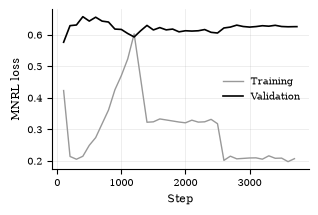

In [12]:
import json, glob
import pandas as pd
import matplotlib.pyplot as plt

run = "models/kb-sbert-en-ms-marco-triplets_3e"
last = max(glob.glob(f"{run}/checkpoint-*"), key=lambda p: int(p.rsplit("-", 1)[1]))
print("Reading", last)

state = json.load(open(f"{last}/trainer_state.json"))
log = pd.DataFrame(state["log_history"])
train = log.dropna(subset=["loss"])
val = log.dropna(subset=["eval_loss"])

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "font.size": 8,
    "axes.labelsize": 8,
    "legend.fontsize": 7,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
})

fig, ax = plt.subplots(figsize=(3.03, 2.0))   # ACL column width × height, in inches
ax.plot(train["step"], train["loss"], color="0.6", lw=1, label="Training")
ax.plot(val["step"], val["eval_loss"], color="black", lw=1.2, label="Validation")
ax.set_xlabel("Step")
ax.set_ylabel("MNRL loss")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(alpha=0.3, lw=0.5)
fig.tight_layout(pad=0.2)

out = os.path.basename(run) + "_loss.pdf"
fig.savefig(out, bbox_inches="tight")
print("Saved", out)
plt.show()